# Oscillatory flow in a compliant tube: streaming

This notebook computes the steady streaming (cycle-averaged) pressure generated by an oscillatory, pressure-driven flow in a weakly deformable axisymmetric tube, a phenomenon known as _elastoinertial rectification_ [ZR24]. It does so in two ways:

1. from the reduced, nonlinear PDE for the pressure of [PWC23], both by a perturbation expansion in the compliance number $\beta\ll1$ and by solving the PDE numerically;
2. from the effective-slip theory of [ZR24], with and without the contribution of advective inertia.

Finally, both theories are compared with the 3D svFSI simulation data of [PWC23].

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

## Notation

Each part of the notebook follows the paper it is based on, as far as practical. The correspondence is:

| This notebook | [PWC23] | [ZR24] | Meaning |
| --- | --- | --- | --- |
| $\mathrm{Wo}$ | $\alpha$ | $\sqrt{\mathcal{W}}$ (their $\alpha = \sqrt{i\mathcal{W}}$) | Womersley number |
| $\beta$ | $\beta$ | $\Lambda$ | compliance (FSI) number |
| $\hat{\mathrm{St}} \equiv \sigma$ | $2\pi\beta St_f$ | $\sigma$ | ratio of flow to oscillation time scales |
| $T$, period $2\pi$ | $T/(2\pi)$, period $1$ | $t$ | time |
| $P_0$, $P_1$ | $P_0$, $P_1$ | $p_1$, $p_2$ | $\mathrm{O}(1)$ and $\mathrm{O}(\beta)$ pressure |
| $\langle V_{z,1}^\mathrm{adv} \rangle$ | &ndash; | $v_{2z}^\mathrm{adv}$ | advective-inertia part of the mean axial velocity |

The cycle average is $\langle \cdot \rangle := \frac{1}{2\pi}\int_0^{2\pi} (\cdot) \, dT$. As in [PWC23] and [ZR24], complex amplitudes are used with the real part understood, and $\mathrm{Re}[\cdot]$ is written out only inside nonlinear terms. For complex amplitudes $A$ and $B$, $\langle \mathrm{Re}[A e^{iT}]\,\mathrm{Re}[B e^{iT}] \rangle = \tfrac{1}{2}\mathrm{Re}[A^* B]$, where $^*$ denotes the complex conjugate.

# Preliminaries

In [1]:
# sympy setup
import sympy as sp
sp.init_printing()

# plotting customizations
from matplotlib import pyplot as plt
size=16
params = {'legend.fontsize': 'large',
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25,
          'font.family': 'serif',
          'mathtext.fontset': 'cm'}
plt.rcParams.update(params)
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

%matplotlib inline
from matplotlib import colormaps

# numerics
import numpy as np
from scipy.integrate import solve_ivp, solve_bvp
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.special import jv, iv

Unless stated otherwise, the plots use the reference parameters below, close to those of the svFSI simulations compared at the end ($\mathrm{Wo}^2 = 1$ to $5$, $\hat{\mathrm{St}} \approx 0.65$). $\beta$ is used only by the numerical solution of the PDE.

In [2]:
Wo_ref = 2.0
St_ref = 0.5
beta_ref = 0.1

# Method of Pande _et al._ (2023)

Common variables, some are explicitly real.

In [3]:
beta, Wo, St = sp.symbols('beta, Wo, St', real=True, positive=True)
P, Z, T = sp.symbols('P, Z, T', real=True)

The governing PDE for the pressure $P(Z,T)$ is [PWC23]
$$
   \frac{\partial }{\partial Z} \left\{ \mathfrak{G}(\beta\,\mathrm{Re}[P];\mathrm{Wo}) \frac{\partial P}{\partial Z} \right\}  = 2 \hat{\mathrm{St}} \left(1+\beta\,\mathrm{Re}[P]\right) \frac{\partial P}{\partial T},
$$
where
$$
  \mathfrak{G}(\beta\,\mathrm{Re}[P]; \mathrm{Wo}) = \left(1+ \beta\,\mathrm{Re}[P]\right)^2 \frac{1}{i \mathrm{Wo}^2} \left[1-\frac{2J_1\left(i^{3/2} {\mathrm{Wo}} \left(1+\beta\,\mathrm{Re}[P]\right)\right)}{i^{3/2} {\mathrm{Wo}} \left(1+\beta\,\mathrm{Re}[P]\right) J_0\left(i^{3/2} {\mathrm{Wo}} \left(1+\beta\,\mathrm{Re}[P]\right)\right)}\right],
$$
subject to $P(0,T) = e^{iT}$ and $P(1,T) = 0$. Here, time is scaled so that the period is $2\pi$, whence $\hat{\mathrm{St}} := 2\pi\beta St_f$ in terms of the Strouhal number $St_f$ of [PWC23]. Only the real part of $P$ enters the deformed radius, $1+\beta\,\mathrm{Re}[P]$; the physical pressure is $\mathrm{Re}[P]$.

## Numerical solution of the PDE

We turn the PDE into a semi-discrete system of ODEs by the [method of lines](https://reference.wolfram.com/language/tutorial/NDSolveMethodOfLines.html), using flux-conservative central differencing with the nonlinear terms staggered (see [\[GC19\]](https://arxiv.org/abs/1903.07568)).

On the grid $Z_j = j\,\Delta Z$ ($j=0,\dots,N-1$), with spacing $\Delta Z = 1/(N-1)$, let $\mathcal{P}_j(T) \approx P(Z_j,T)$. For the interior nodes ($j=1,\dots,N-2$),
$$
   \frac{d\mathcal{P}_j}{dT} = \frac{1}{2 \hat{\mathrm{St}} \left(1+\beta\,\mathrm{Re}[\mathcal{P}_j]\right)} \frac{ S_{j+1/2}\, \mathfrak{G}(\beta\,\mathrm{Re}[\mathcal{P}_{j+1/2}];\mathrm{Wo}) - S_{j-1/2}\, \mathfrak{G}(\beta\,\mathrm{Re}[\mathcal{P}_{j-1/2}];\mathrm{Wo})}{\Delta Z},
$$
where
$$
\begin{aligned}
  S_{j+1/2} &:= \left.\frac{\partial P}{\partial Z}\right|_{Z_{j+1/2}} \approx \frac{\mathcal{P}_{j+1} - \mathcal{P}_{j}}{\Delta Z}, &\qquad \mathcal{P}_{j+1/2} &\approx \frac{\mathcal{P}_{j+1} + \mathcal{P}_{j}}{2},\\
  S_{j-1/2} &:= \left.\frac{\partial P}{\partial Z}\right|_{Z_{j-1/2}} \approx \frac{\mathcal{P}_j - \mathcal{P}_{j-1}}{\Delta Z}, &\qquad \mathcal{P}_{j-1/2} &\approx \frac{\mathcal{P}_j + \mathcal{P}_{j-1}}{2}.
\end{aligned}
$$
At $Z=0$ ($j=0$) and $Z=1$ ($j=N-1$), we impose the Dirichlet BCs
$$
  \mathcal{P}_0(T) = e^{iT}, \qquad \mathcal{P}_{N-1}(T) = 0.
$$
As in [PWC23], we start from $P(Z,0) = 0$ and integrate long enough for the initial transient to decay.

In [4]:
# number of grid points
N = 500
# the grid and its spacing
Zj = np.linspace(0,1,num=N,endpoint=True)
dZ = Zj[1] - Zj[0]
# time span of numerical integration: 8 periods
Tmax = 8*(2*np.pi)

In [5]:
# only the real part of beta*P enters the deformed radius, 1 + beta*Re[P]
def mathfrak_G(betaP,Wo):
  a = 1 + np.real(betaP)
  return a**2/(1j*Wo**2) \
           * (1 - 2*jv(1,1j**(3/2)*Wo*a)/(1j**(3/2)*Wo*a*jv(0,1j**(3/2)*Wo*a)))

In [6]:
def P_left_BC(T):
  return np.exp(1j*T)

def P_right_BC(T):
  return 0.

In [7]:
# semi-discrete ODE system's right-hand side, for the interior nodes j = 1, ..., N-2
def PWC23_PDE_RHS(T,P,beta,St,Wo):
  # neighbors of each interior node, using the Dirichlet BCs at the ends
  Pm1 = np.concatenate(([P_left_BC(T)], P[0:N-3]))
  Pp1 = np.concatenate((P[1:N-2], [P_right_BC(T)]))

  # values and slopes at j -/+ 1/2
  Pm12 = (P + Pm1)/2
  Pp12 = (Pp1 + P)/2
  Sm12 = (P - Pm1)/dZ
  Sp12 = (Pp1 - P)/dZ

  return (mathfrak_G(beta*Pp12,Wo)*Sp12 - mathfrak_G(beta*Pm12,Wo)*Sm12)/dZ \
         /(2*St*(1 + beta*np.real(P)))

The `Radau` and `LSODA` methods of `solve_ivp` do not support complex-valued solutions.

The problem is stiff, so the explicit Runge&ndash;Kutta methods are slow. `BDF` works well.

In [8]:
my_beta = beta_ref
my_St = St_ref
my_Wo = Wo_ref

# integration method and solver tolerance(s)
intmeth = 'BDF'
tol = 1e-8

# zero initial condition, as in [PWC23]
Pic = np.zeros(N-2, dtype=complex)

# simulate the PDE
sol = solve_ivp(fun=lambda T, P: PWC23_PDE_RHS(T,P,my_beta,my_St,my_Wo),
                t_span=[0,Tmax], y0=Pic,
                method=intmeth, rtol=tol, atol=tol, dense_output=True)

## Perturbation expansion

For $\beta\ll1$, we expand $P = P_0 + \beta P_1 + \mathrm{O}(\beta^2)$ and $\mathfrak{G} = \mathfrak{g}_0(\mathrm{Wo}) + \beta\,\mathrm{Re}[P]\,\mathfrak{g}_1(\mathrm{Wo}) + \mathrm{O}(\beta^2)$, where [PWC23]
$$
\begin{aligned}
  \mathfrak{g}_0(\mathrm{Wo}) &= \frac{1}{i\mathrm{Wo}^2}\left[1-\frac{2J_1\left(i^{3/2}\mathrm{Wo}\right)}{i^{3/2}\mathrm{Wo}\,J_0\left(i^{3/2}\mathrm{Wo}\right)}\right] = \frac{I_2\left(\sqrt{i}\,\mathrm{Wo}\right)}{i\mathrm{Wo}^2\, I_0\left(\sqrt{i}\,\mathrm{Wo}\right)},\\
  \mathfrak{g}_1(\mathrm{Wo}) &= -\frac{2J_1\left(i^{3/2}\mathrm{Wo}\right)^2}{i\mathrm{Wo}^2\, J_0\left(i^{3/2}\mathrm{Wo}\right)^2}.
\end{aligned}
$$
The second form of $\mathfrak{g}_0$, in terms of modified Bessel functions, is the one used by [ZR24]. The cells below derive both coefficients from $\mathfrak{G}$ and check them against these formulas.

Unlike [PWC23], who take $\beta St_f = \mathrm{O}(\beta)$, so that the leading-order flow is quasi-steady, here we keep $\hat{\mathrm{St}} = \mathrm{O}(1)$. The $\mathrm{O}(1)$ problem is then an unsteady diffusion equation, and $\hat{\mathrm{St}}$ also forces the $\mathrm{O}(\beta)$ problem. The streaming pressure of [PWC23] is recovered as $\hat{\mathrm{St}}\to0$, which we check below.

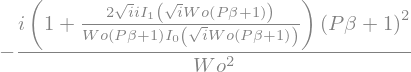

In [9]:
G = (1 + beta*P)**2*1/(sp.I*Wo**2) \
    * (1 - 2*sp.besselj(1,sp.I**sp.Rational(3,2)*Wo*(1+beta*P)) \
           /sp.besselj(0,sp.I**sp.Rational(3,2)*Wo*(1+beta*P)) \
           /(sp.I**sp.Rational(3,2)*Wo*(1+beta*P)) )

display(G)

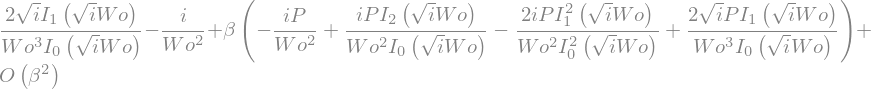

In [10]:
Gseries = sp.series(G,beta,0,2)
display(Gseries)

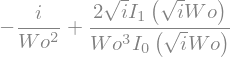

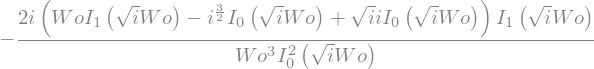

In [11]:
G0 = sp.limit(Gseries,beta,0).simplify()
display(G0)
G1 = sp.limit((Gseries-G0)/(beta*P),beta,0).simplify()
display(G1)

In [12]:
# check that G0 is the same as in Zhang and Rallabandi (2024)
sp.Eq(G0,sp.besseli(2,sp.I**sp.Rational(1,2)*Wo)/sp.I/Wo**2/sp.besseli(0,sp.I**sp.Rational(1,2)*Wo)).simplify()

In [13]:
# check that G1 is the same as in Pande et al. (2023)
sp.Eq(G1,-2*sp.besselj(1,sp.I**sp.Rational(3,2)*Wo)**2/sp.I/Wo**2/sp.besselj(0,sp.I**sp.Rational(3,2)*Wo)**2).simplify()

### At $\mathrm{O}(1)$

At $\mathrm{O}(1)$, we have
$$
\begin{aligned}
    \mathfrak{g}_0 \frac{\partial^2 P_0}{\partial Z^2} &= 2\hat{\mathrm{St}}\frac{\partial P_0}{\partial T},\\
    P_0(0,T) &= e^{i T},\\
    P_0(1,T) &= 0.
\end{aligned}
$$
The solution is of the form $P_0(Z,T) = P_{0,a}(Z) e^{i T}$, where $\mathfrak{g}_0 P_{0,a}'' = 2i\hat{\mathrm{St}}P_{0,a}$, $P_{0,a}(0) = 1$, and $P_{0,a}(1) = 0$.

In [14]:
g0, g1 = sp.symbols('g0, g1')

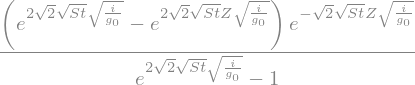

In [15]:
f = sp.Function('f')
P0asol = sp.dsolve(g0*f(Z).diff(Z,Z) - 2*St*sp.I*f(Z),
                    f(Z), ics={f(0):1, f(1):0}).rhs.simplify()
display(P0asol)

In [16]:
lam_P0_PWC23 = sp.lambdify((Z,T,St,Wo), sp.re(P0asol.subs(g1,G1).subs(g0,G0)*sp.exp(sp.I*T)))

### At $\mathrm{O}(\beta)$

At $\mathrm{O}(\beta)$, we have
$$
\begin{aligned}
    \mathfrak{g}_0 \frac{\partial^2 P_1}{\partial Z^2} +
    \mathfrak{g}_1 \frac{\partial}{\partial Z} \left(\mathrm{Re}[P_0]\frac{\partial P_0}{\partial Z}\right)
    &= 2\hat{\mathrm{St}} \frac{\partial P_1}{\partial T} + 2\hat{\mathrm{St}}\, \mathrm{Re}[P_0] \frac{\partial P_0}{\partial T}, \\
    P_1(0,T) &= 0, \\
    P_1(1,T) &= 0.
\end{aligned}
$$
Since $\mathrm{Re}[P_0] = \tfrac{1}{2}\left(P_{0,a}e^{iT} + P_{0,a}^*e^{-iT}\right)$, the forcing has only a steady part and a second harmonic, so
$$
    P_1(Z,T) = P_{1,0,a}(Z) + P_{1,2,a}(Z) e^{2i T}.
$$
The steady term satisfies
$$
    \mathfrak{g}_0 \frac{d^2 P_{1,0,a}}{d Z^2} + \frac{1}{2} \mathfrak{g}_1 \frac{d}{d Z} \left(P_{0,a}^* \frac{d P_{0,a}}{d Z}\right) - i \hat{\mathrm{St}} P_{0,a}^* P_{0,a} = 0, \qquad P_{1,0,a}(0) = P_{1,0,a}(1) = 0,
$$
and the streaming pressure is $\langle P_1 \rangle = \mathrm{Re}[P_{1,0,a}]$.

This ODE is elementary once its forcing terms are written in real form. With $u := 1-Z$ and $\kappa = \kappa_r + i\kappa_i$,
$$
  P_{0,a}^* P_{0,a} = \frac{\cosh(2\kappa_r u)-\cos(2\kappa_i u)}{2|\sinh\kappa|^2},\qquad
  P_{0,a}^*\frac{dP_{0,a}}{dZ} = -\kappa\,\frac{\sinh(2\kappa_r u)-i\sin(2\kappa_i u)}{2|\sinh\kappa|^2},
$$
where $|\sinh\kappa|^2 = \tfrac{1}{2}\left[\cosh(2\kappa_r) - \cos(2\kappa_i)\right]$. Integrating twice and imposing $P_{1,0,a}(0) = P_{1,0,a}(1) = 0$ gives
$$
  P_{1,0,a}(Z) = H(Z) - (1-Z)H(0) - Z H(1),
$$
$$
  H(Z) = \frac{1}{2\mathfrak{g}_0|\sinh\kappa|^2}\left[-\frac{\mathfrak{g}_1\kappa}{2}\left(\frac{\cosh(2\kappa_r u)}{2\kappa_r} + i\,\frac{\cos(2\kappa_i u)}{2\kappa_i}\right) + i\hat{\mathrm{St}}\left(\frac{\cosh(2\kappa_r u)}{4\kappa_r^2} + \frac{\cos(2\kappa_i u)}{4\kappa_i^2}\right)\right].
$$
The first term is the flux generated by the wall motion, and the second is the storage term. Below, SymPy checks the two identities and carries out the integration.

In [17]:
# kappa = kappa_r + i kappa_i, and u = 1 - Z
kr, ki = sp.symbols('kappa_r, kappa_i', real=True, nonzero=True)
kappa_c = kr + sp.I*ki
u = 1 - Z
P0a_c = sp.sinh(kappa_c*u)/sp.sinh(kappa_c)
abs_sinh2 = (sp.cosh(2*kr) - sp.cos(2*ki))/2
absP0a2 = (sp.cosh(2*kr*u) - sp.cos(2*ki*u))/(2*abs_sinh2)
P0astar_dP0a = -kappa_c*(sp.sinh(2*kr*u) - sp.I*sp.sin(2*ki*u))/(2*abs_sinh2)

# check the two identities at sample values of kappa
for lhs, rhs in [(sp.conjugate(P0a_c)*P0a_c, absP0a2),
                 (sp.conjugate(P0a_c)*P0a_c.diff(Z), P0astar_dP0a)]:
  residual = sp.lambdify((Z, kr, ki), lhs - rhs)
  my_res = max(abs(residual(my_Zval, 0.7, -1.3)) for my_Zval in np.linspace(0,1,11))
  print(f'identity residual: {my_res:.1e}')

identity residual: 3.3e-16
identity residual: 6.0e-16


In [18]:
# integrate g0 P'' = -(1/2) g1 (P0a* P0a')' + i St |P0a|^2 twice, then impose P(0) = P(1) = 0
c0, c1 = sp.symbols('c0, c1')
dP10a = (-sp.Rational(1,2)*g1*P0astar_dP0a + sp.I*St*sp.integrate(absP0a2, (Z, 0, Z)))/g0 + c1
P10asol = sp.integrate(dP10a, (Z, 0, Z)) + c0
P10asol = P10asol.subs(sp.solve([P10asol.subs(Z, 0), P10asol.subs(Z, 1)], [c0, c1]))

lam_P10a = sp.lambdify((Z, St, kr, ki, g0, g1), P10asol)

In [19]:
# g0 in the form of [ZR24], g1 in the form of [PWC23] (both checked against G0, G1 above)
def g0_num(Wo):
  a = np.sqrt(1j)*Wo
  return iv(2, a)/(1j*Wo**2*iv(0, a))

def g1_num(Wo):
  a = 1j**(3/2)*Wo
  return -2*jv(1, a)**2/(1j*Wo**2*jv(0, a)**2)

# P_{1,0,a}(Z) and the streaming pressure <P_1> = Re[P_{1,0,a}]
def lam_streamP_PWC23_complex(Z,St,Wo):
  g0 = g0_num(Wo)
  g1 = g1_num(Wo)
  kappa = np.sqrt(2j*St/g0)
  return lam_P10a(Z, St, kappa.real, kappa.imag, g0, g1)

def lam_streamP_PWC23(Z,St,Wo):
  return np.real(lam_streamP_PWC23_complex(Z,St,Wo))

As $\hat{\mathrm{St}}\to0$, $\langle P_1 \rangle$ tends to the result of [PWC23], $\tfrac{1}{4}Z(1-Z)\,\mathrm{Re}[\mathfrak{g}_1/\mathfrak{g}_0]$:

In [20]:
my_Wo = Wo_ref
my_Z = np.linspace(0,1,100,endpoint=True)
my_streamP_qs = 0.25*my_Z*(1-my_Z)*np.real(g1_num(my_Wo)/g0_num(my_Wo))

for my_St_small in [1e-1, 1e-2, 1e-3]:
  my_err = np.max(np.abs(lam_streamP_PWC23(my_Z,my_St_small,my_Wo) - my_streamP_qs))
  print(f'Wo = {my_Wo}, St = {my_St_small:g}: max difference = {my_err:.2e}')

Wo = 2.0, St = 0.1: max difference = 1.80e-02
Wo = 2.0, St = 0.01: max difference = 2.76e-03
Wo = 2.0, St = 0.001: max difference = 2.83e-04


The second-harmonic term satisfies
$$
    \mathfrak{g}_0 \frac{d^2 P_{1,2,a}}{d Z^2}
    + \frac{1}{2} \mathfrak{g}_1 \frac{d}{d Z} \left( P_{0,a} \frac{d P_{0,a}}{d Z} \right) - 4i \hat{\mathrm{St}} P_{1,2,a} - i \hat{\mathrm{St}} P_{0,a}^2 = 0, \qquad P_{1,2,a}(0) = P_{1,2,a}(1) = 0.
$$
It does not contribute to the cycle average, so we do not solve it here.

## Numerical solution vs perturbation

We compare the pressure from the PDE (solid) with the leading-order perturbation solution, $\mathrm{Re}[P_0]$ (dashed), over the last computed period.

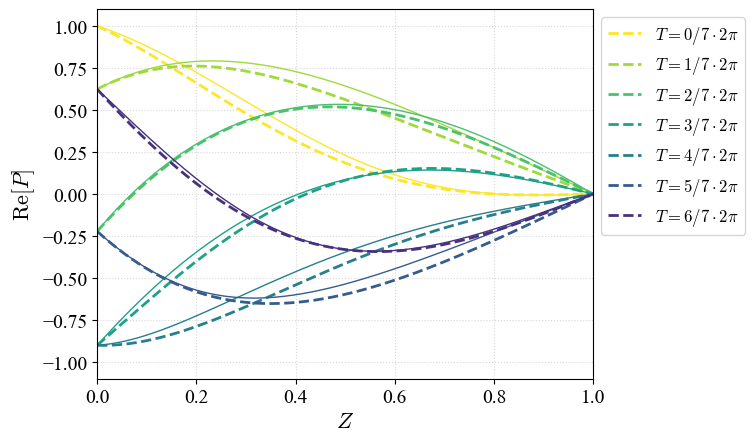

beta = 0.1, Wo = 2.0, St = 0.5
dashed = perturbation, solid = PDE


In [21]:
my_beta = beta_ref
my_St = St_ref
my_Wo = Wo_ref

ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\mathrm{Re}[P]$')
ax.set_xlim(0, 1)
ax.set_ylim(-1.1, 1.1)

# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis_r']

T0 = Tmax-2*np.pi
jmax = 7
for j in range(0,jmax):
  Tj = T0+j/jmax*2*np.pi
  my_P0 = lam_P0_PWC23(Zj,Tj,my_St,my_Wo)
  ax.plot(Zj, my_P0, lw=2, ls='dashed', label=rf'$T={j}/{jmax}\cdot 2\pi$', color=cmap(j/jmax))
  Pj = np.concatenate(([P_left_BC(Tj)], sol.sol(Tj), [P_right_BC(Tj)]))
  ax.plot(Zj, np.real(Pj), lw=1, color=cmap(j/jmax))

ax.grid(alpha=0.5, linestyle='dotted')

# put a legend to the right of the current axis
ax.legend(bbox_to_anchor=(1, 1))

plt.show()

print(f'beta = {my_beta}, Wo = {my_Wo}, St = {my_St}')
print('dashed = perturbation, solid = PDE')

### Streaming: PDE vs perturbation

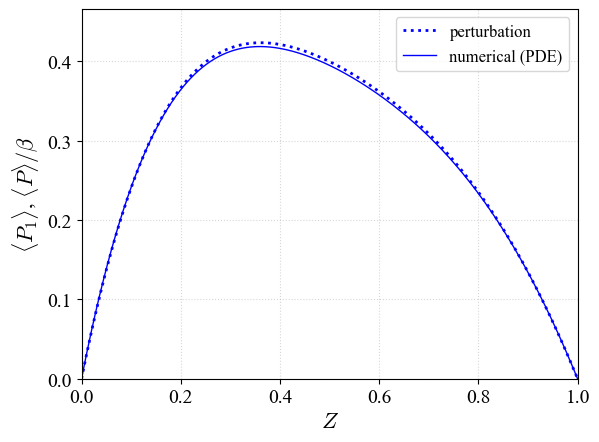

beta = 0.1, Wo = 2.0, St = 0.5


In [22]:
my_streamP = lam_streamP_PWC23(Zj,my_St,my_Wo)
# cycle average over the last computed period
my_Ts = np.linspace(T0,T0+2*np.pi,50,endpoint=True)

sol_space_time = np.concatenate(([P_left_BC(my_Ts)], sol.sol(my_Ts), [np.zeros_like(my_Ts)]))
my_numerical_streamP = np.real(trapezoid(sol_space_time,my_Ts,axis=1)/(2*np.pi))/my_beta

ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\langle P_1 \rangle$, $\langle P \rangle/\beta$')
ax.set_xlim(0, 1)
ylim_max = float(1.1*max(np.max(my_streamP),
                         np.max(my_numerical_streamP)))
ax.set_ylim(0, ylim_max)

ax.plot(Zj, my_streamP, lw=2, ls='dotted', color='blue', label='perturbation')
ax.plot(Zj, my_numerical_streamP, lw=1, color='blue', label='numerical (PDE)')

ax.grid(alpha=0.5, linestyle='dotted')

ax.legend()

plt.show()

print(f'beta = {my_beta}, Wo = {my_Wo}, St = {my_St}')

At $\beta = 0.1$, the streaming pressure from the PDE agrees with the $\mathrm{O}(\beta)$ perturbation result to within about 1%; the difference is $\mathrm{O}(\beta)$ and vanishes as $\beta\to0$.

# Method of Zhang &amp; Rallabandi (2024)

In [23]:
# fresh symbols for this section; this Wo (real) is a different SymPy symbol from the
# one above (real, positive), but lambdify treats both as 'Wo'
kappa = sp.symbols('kappa')
Wo, R, Z, T = sp.symbols('Wo, R, Z, T', real=True)

As in [PWC23], $P_0(Z,T) = P_{0,a}(Z) e^{iT}$, where
$$
  P_{0,a}(Z) = \frac{\sinh\big(\kappa(1-Z)\big)}{\sinh \kappa},\qquad \kappa(\mathrm{Wo}) := \sqrt{\frac{2i\sigma}{\mathfrak{g}_0(\mathrm{Wo})}},\quad \sigma \equiv \hat{\mathrm{St}}.
$$
This is also the leading-order pressure of [ZR24], whose $k$ equals $\kappa$.

In [24]:
P0a = sp.sinh(kappa*(1-Z))/sp.sinh(kappa)
P0 = P0a*sp.exp(sp.I*T)

The leading-order axial velocity is the Womersley profile [ZR24], $V_{z,0}(R,Z,T) = V_{z,0,a}(R,Z) e^{iT}$, where
$$
    V_{z,0,a}(R,Z) =
    \frac{1}{i\mathrm{Wo}^2}\left[1-\frac{J_0(i^{3/2} \mathrm{Wo} \,R)}{J_0(i^{3/2} \mathrm{Wo} )}\right] \left( -\frac{d P_{0,a}}{d Z} \right).
$$

In [25]:
Vz0a = 1/(sp.I*Wo**2)*(1 - sp.besselj(0,sp.I**sp.Rational(3,2)*Wo*R) \
                           /sp.besselj(0,sp.I**sp.Rational(3,2)*Wo))*(-P0a.diff(Z))
Vz0 = Vz0a*sp.exp(sp.I*T)

From the continuity equation,
$$
  \frac{1}{R}\frac{\partial(R V_{r,0,a})}{\partial R} + \frac{\partial V_{z,0,a}}{\partial Z} = 0,
$$
the radial velocity $V_{r,0,a}$ is found by integrating in $R$, requiring regularity at $R=0$.

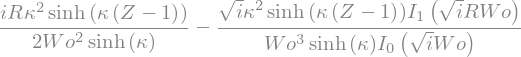

In [26]:
f = sp.Function('f')
Vr0a = sp.dsolve(1/R*(R*f(R)).diff(R) + Vz0a.diff(Z), f(R)).rhs #.simplify()
# apply centerline condition by hand to find constant of integration
my_C1 = sp.solve(sp.limit(R**2*Vr0a.diff(R),R,0))[0]
Vr0a = Vr0a.subs({sp.Symbol('C1'): my_C1})
display(Vr0a)
Vr0 = Vr0a*sp.exp(sp.I*T)

Following [ZR24], the $\mathrm{O}(\beta)$ mean flow is driven by an effective slip velocity at the undeformed wall (from Taylor-expanding the no-slip condition about $R=1$),
$$
  v_\mathrm{slip}(Z) := -\left.\left\langle P_0 \frac{\partial V_{z,0}}{\partial R} \right\rangle\right|_{R=1},
$$
and by advective inertia, through $\langle V_{z,1}^\mathrm{adv} \rangle$ (evaluated in the next section). From $V_{z,0,a}$ above,
$$
  v_\mathrm{slip}(Z) = \tfrac{1}{2}\mathrm{Re}\left[ s(\mathrm{Wo})\, P_{0,a}^* \frac{dP_{0,a}}{dZ} \right], \qquad
  s(\mathrm{Wo}) := \frac{i^{3/2}\mathrm{Wo}\, J_1\left(i^{3/2}\mathrm{Wo}\right)}{i\mathrm{Wo}^2\, J_0\left(i^{3/2}\mathrm{Wo}\right)}.
$$
Neglecting advective inertia for now, [ZR24]
$$
    \langle Q_1 \rangle = 2\pi \int_0^1 \tfrac{1}{2} v_\mathrm{slip}(Z) \, dZ
    \qquad\text{and}\qquad
    \langle P_1 \rangle(Z) = 16 \int_0^Z \tfrac{1}{2} v_\mathrm{slip}(Z') \, dZ' - \frac{8}{\pi} Z \langle Q_1 \rangle,
$$
so that $\langle P_1 \rangle(0) = \langle P_1 \rangle(1) = 0$. The cycle averages are evaluated as $\langle A B \rangle = \tfrac{1}{2}\mathrm{Re}[A^*B]$.

In [27]:
Q1_ZR24 = 2*sp.pi*sp.re(sp.integrate((-1/2)*(1/2)*sp.conjugate(P0)*Vz0.diff(R).subs(R,1),(Z,0,1))).subs(kappa,sp.sqrt(2*sp.I*St/G0))

In [28]:
ZZ = sp.Symbol('ZZ')
P1_ZR24 = 16*sp.re(sp.integrate((-1/2)*(1/2)*sp.conjugate(P0)*Vz0.diff(R).subs(R,1),(Z,0,ZZ))).subs(kappa,sp.sqrt(2*sp.I*St/G0)).subs(ZZ,Z) - (8/sp.pi)*Z*Q1_ZR24

In [29]:
# this P_1 is the streaming pressure, by construction, in ZR24
lam_streamP_ZR24 = sp.lambdify((Z,St,Wo), P1_ZR24)

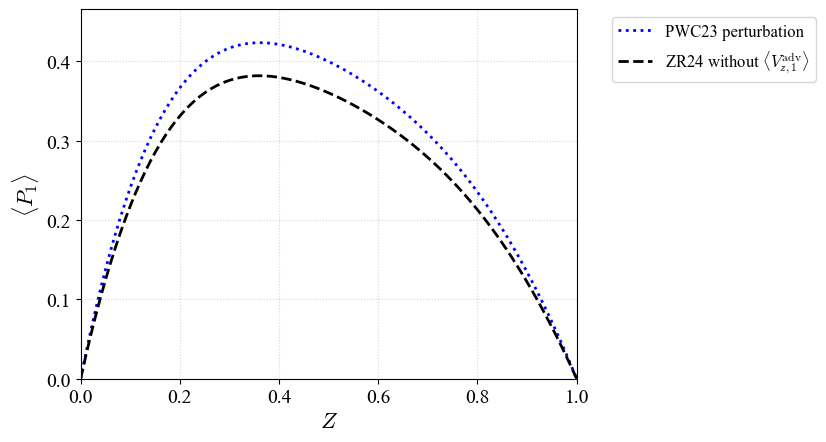

Wo = 2.0, St = 0.5


In [30]:
my_St = St_ref
my_Wo = Wo_ref

my_Z = np.linspace(0,1,100,endpoint=True)
my_streamP_ZR24 = lam_streamP_ZR24(my_Z,my_St,my_Wo)
my_streamP_PWC23 = lam_streamP_PWC23(my_Z,my_St,my_Wo)

ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\langle P_1 \rangle$')
ax.set_xlim(0, 1)
ylim_max = float(1.1*max(np.max(my_streamP_ZR24),
                         np.max(my_streamP_PWC23)))
ax.set_ylim(0, ylim_max)

ax.plot(my_Z, my_streamP_PWC23, ls='dotted', color='blue', lw=2,
        label='PWC23 perturbation')
ax.plot(my_Z, my_streamP_ZR24, ls='dashed', color='black', lw=2,
        label=r'ZR24 without $\langle V_{z,1}^\mathrm{adv} \rangle$')

ax.grid(alpha=0.5, linestyle='dotted')

ax.legend(bbox_to_anchor=(1, 0, 0.5, 1), loc='upper right')

plt.show()

print(f'Wo = {my_Wo}, St = {my_St}')

## How the two formulations differ

Without advective inertia, both theories determine the streaming pressure from a mean-flux balance. In [PWC23], from the $\mathrm{O}(\beta)$ steady equation above,
$$
  \mathfrak{g}_0(\mathrm{Wo}) \frac{d^2 P_{1,0,a}}{dZ^2} = -\tfrac{1}{2}\mathfrak{g}_1(\mathrm{Wo}) \frac{d}{dZ}\left(P_{0,a}^*\frac{dP_{0,a}}{dZ}\right) + i\hat{\mathrm{St}}\, P_{0,a}^*P_{0,a}, \qquad \langle P_1\rangle = \mathrm{Re}[P_{1,0,a}],
$$
while in [ZR24], differentiating the formula for $\langle P_1 \rangle$ twice,
$$
  \frac{1}{8} \frac{d^2 \langle P_1\rangle}{dZ^2} = \mathrm{Re}\left[\tfrac{1}{2} s(\mathrm{Wo}) \frac{d}{dZ}\left(P_{0,a}^*\frac{dP_{0,a}}{dZ}\right)\right].
$$
The two differ in three ways:

1. **Resistance to the mean flow.** [PWC23] use the oscillatory (Womersley) coefficient $\mathfrak{g}_0(\mathrm{Wo})$ for the mean flow too, whereas [ZR24] use the steady Poiseuille value $1/8$.
2. **Flux generated by the wall motion.** In [PWC23], it comes from the Womersley flux in the instantaneously deformed tube, with coefficient $-\tfrac{1}{2}\mathfrak{g}_1$. In [ZR24], it comes from the slip velocity at the undeformed wall, with coefficient $\tfrac{1}{2}s$.
3. **The $i\hat{\mathrm{St}}\,|P_{0,a}|^2$ term** is purely imaginary, so it affects $\langle P_1 \rangle$ only through the complex $\mathfrak{g}_0$. In [ZR24], the corresponding cycle average of $p\,\partial p/\partial t$ vanishes.

As $\mathrm{Wo}\to0$, $\mathfrak{g}_0 \to 1/8$ and $-\tfrac{1}{2}\mathfrak{g}_1, \tfrac{1}{2}s \to -1/4$, so the two theories agree. The coefficients separate as $\mathrm{Wo}$ grows:

In [31]:
def s_num(Wo):
  a = 1j**(3/2)*Wo
  return a*jv(1, a)/(1j*Wo**2*jv(0, a))

print(f"{'Wo':>5} {'g0':>17} {'1/8':>6} {'-g1/2':>17} {'s/2':>17}")
for my_Wo in [0.1, 1, 2, 3]:
  print(f'{my_Wo:5.1f} {g0_num(my_Wo):17.4f} {1/8:6.3f} {-g1_num(my_Wo)/2:17.4f} {s_num(my_Wo)/2:17.4f}')

   Wo                g0    1/8             -g1/2               s/2
  0.1    0.1250-0.0002j  0.125   -0.2500+0.0006j   -0.2500+0.0003j
  1.0    0.1215-0.0202j  0.125   -0.2363+0.0595j   -0.2449+0.0304j
  2.0    0.0862-0.0566j  0.125   -0.1199+0.1334j   -0.1934+0.0862j
  3.0    0.0400-0.0557j  0.125   -0.0299+0.0898j   -0.1248+0.0900j


At the reference parameters ($\mathrm{Wo}=2$), the coefficients already differ substantially, and the peak streaming pressure of [PWC23] in the plot before this section exceeds that of [ZR24] without advective inertia by about 10%. The svFSI comparison at the end shows the same trend.

## Evaluating the advective inertia's contribution

Next, we evaluate the cycle-averaged advective inertia,
$$
  \left\langle V_{r,0} \frac{\partial V_{z,0}}{\partial R} + V_{z,0} \frac{\partial V_{z,0}}{\partial Z} \right\rangle = \left\langle V_{r,0} \frac{\partial V_{z,0}}{\partial R} \right\rangle + \left\langle V_{z,0} \frac{\partial V_{z,0}}{\partial Z} \right\rangle.
$$

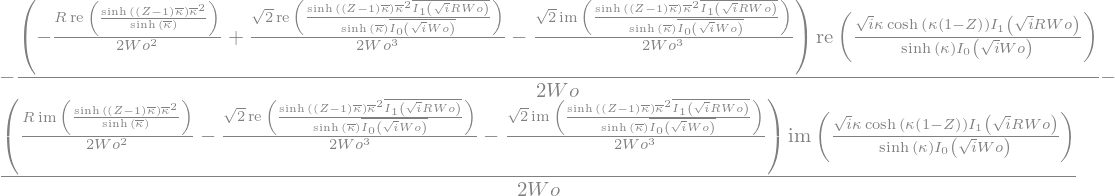

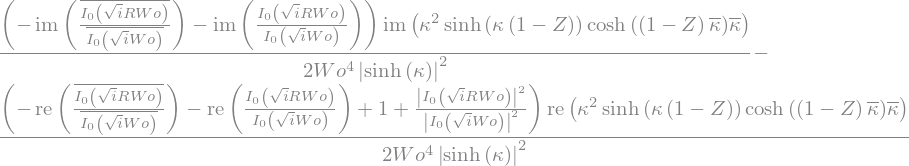

In [32]:
inertia_avg_term1 = sp.Rational(1,2)*sp.re(sp.conjugate(Vr0)*Vz0.diff(R))
display(inertia_avg_term1)
inertia_avg_term2 = sp.Rational(1,2)*sp.re(sp.conjugate(Vz0)*Vz0.diff(Z))
display(inertia_avg_term2)

These expressions are lengthy, and a series expansion for $\mathrm{Wo}\ll1$ did not prove useful, so we evaluate them numerically.

Following [ZR24], $\langle V_{z,1}^\mathrm{adv} \rangle$ satisfies the BVP
$$
  \frac{\mathrm{Wo}^2}{\sigma} \left\langle V_{r,0} \frac{\partial V_{z,0}}{\partial R} + V_{z,0} \frac{\partial V_{z,0}}{\partial Z} \right\rangle =  \frac{1}{R}\frac{\partial }{\partial R} \left( R \frac{\partial
   \langle V_{z,1}^\mathrm{adv} \rangle}{\partial R} \right) = \frac{\partial^2 \langle V_{z,1}^\mathrm{adv} \rangle}{\partial R^2} +  \frac{1}{R}\frac{\partial \langle V_{z,1}^\mathrm{adv} \rangle}{\partial R},
$$
$$
  \left.\frac{\partial \langle V_{z,1}^\mathrm{adv} \rangle}{\partial R}\right|_{R=0} = \langle V_{z,1}^\mathrm{adv} \rangle|_{R=1} = 0,
$$
where [ZR24] write the prefactor as $\mathcal{W}/\sigma$. We solve it numerically, starting the grid just off $R=0$ to avoid the coordinate singularity.

In [33]:
avg_Vz1_adv_forcing = sp.lambdify((R,Z,St,Wo), Wo**2/St*(inertia_avg_term1+inertia_avg_term2).subs(kappa,sp.sqrt(2*sp.I*St/G0)))

In [34]:
def avg_Vz1_ode(R, V, Z, St, Wo):
  return np.vstack((V[1,:], avg_Vz1_adv_forcing(R,Z,St,Wo) - 1/R*V[1,:]))

def avg_Vz1_bc(Va, Vb):
  return np.array([Va[1], Vb[0]])

my_R = np.linspace(1e-6,1,100,endpoint=True) # avoid R = 0 singularity
V_guess = np.vstack((1-my_R**2,-2*my_R))

# finds $\langle V_{z,1}^\mathrm{adv} \rangle$
def Vz1_adv(Z,St,Wo):
  sol = solve_bvp(lambda R, V: avg_Vz1_ode(R, V, Z, St, Wo), avg_Vz1_bc, my_R, V_guess)
  return sol.sol(my_R)[0,:]

# computes $\int_0^1 \langle V_{z,1}^\mathrm{adv} \rangle R dR$
# allows for a vector input of Z values
def rint_Vz1_adv(Z,St,Wo):
  if np.isscalar(Z):
    sol = solve_bvp(lambda R, V: avg_Vz1_ode(R, V, Z, St, Wo), avg_Vz1_bc, my_R, V_guess)
    return trapezoid(sol.sol(my_R)[0,:]*my_R,my_R)
  else:
    output_array = np.zeros_like(Z)
    for i in range(0,Z.size):
      sol = solve_bvp(lambda R, V: avg_Vz1_ode(R, V, Z[i], St, Wo), avg_Vz1_bc, my_R, V_guess)
      output_array[i] = trapezoid(sol.sol(my_R)[0,:]*my_R,my_R)
    return output_array

We plot $\langle V_{z,1}^\mathrm{adv} \rangle$ as a function of $R$ at different $Z$ locations, each normalized by its maximum magnitude (given in the legend) to fit on one plot.

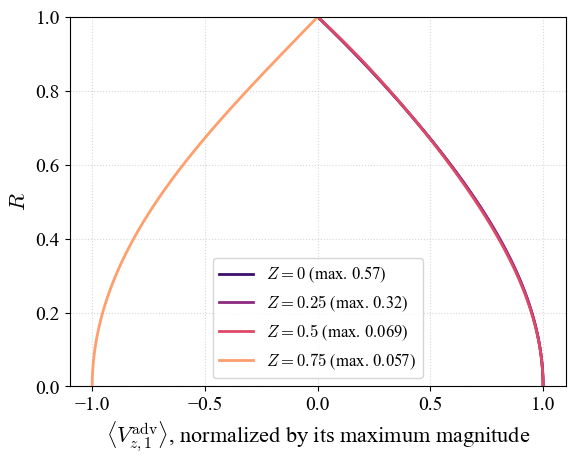

Wo = 2.0, St = 0.5


In [35]:
my_St = St_ref
my_Wo = Wo_ref

ax = plt.gca()
ax.set_ylabel('$R$')
ax.set_xlabel(r'$\langle V_{z,1}^\mathrm{adv} \rangle$, normalized by its maximum magnitude')
ax.set_ylim(0, 1)

# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['magma']

for j, my_Zval in enumerate([0, 0.25, 0.5, 0.75]):
  my_Vz1_adv = Vz1_adv(my_Zval, my_St, my_Wo)
  my_max = np.max(np.abs(my_Vz1_adv))
  ax.plot(my_Vz1_adv/my_max, my_R, lw=2,
          label=f'$Z={my_Zval}$ (max. {my_max:.2g})', color=cmap((j+1)/5))

ax.grid(alpha=0.5, linestyle='dotted')
ax.legend()

plt.show()

print(f'Wo = {my_Wo}, St = {my_St}')

Now, we redo the $\langle P_1 \rangle$ plot including $\langle V_{z,1}^\mathrm{adv} \rangle$. From [ZR24],
$$
    \langle Q_1 \rangle = 2\pi \int_0^1 \left[ \tfrac{1}{2} v_\mathrm{slip}(Z) + \int_0^1 \langle V_{z,1}^\mathrm{adv} \rangle \, R \, dR \right] dZ
$$
and
$$
    \langle P_1 \rangle(Z) = 16 \int_0^Z \left[ \tfrac{1}{2} v_\mathrm{slip}(Z') + \int_0^1 \langle V_{z,1}^\mathrm{adv} \rangle \, R \, dR \right] dZ' - \frac{8}{\pi} Z \langle Q_1 \rangle.
$$

In [36]:
my_St = St_ref
my_Wo = Wo_ref
my_Z = np.linspace(0,1,100,endpoint=True)

my_streamP_ZR24 = lam_streamP_ZR24(my_Z,my_St,my_Wo)

my_rint_Vz1_adv = rint_Vz1_adv(my_Z,my_St,my_Wo)

my_streamP_ZR24_w_Vz1_adv = lam_streamP_ZR24(my_Z,my_St,my_Wo) \
                            + 16*cumulative_trapezoid(my_rint_Vz1_adv,my_Z,initial=0) \
                            - 16*my_Z*trapezoid(my_rint_Vz1_adv,my_Z)

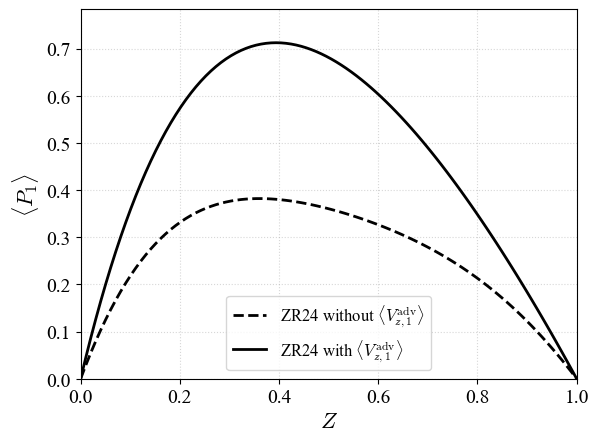

Wo = 2.0, St = 0.5


In [37]:
ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\langle P_1 \rangle$')
ax.set_xlim(0, 1)
ylim_max = float(1.1*max(np.max(my_streamP_ZR24),
                         np.max(my_streamP_ZR24_w_Vz1_adv)))
ax.set_ylim(0, ylim_max)

ax.plot(my_Z, my_streamP_ZR24, lw=2, ls='dashed', color='black',
        label=r'ZR24 without $\langle V_{z,1}^\mathrm{adv} \rangle$')
ax.plot(my_Z, my_streamP_ZR24_w_Vz1_adv, lw=2, color='black',
        label=r'ZR24 with $\langle V_{z,1}^\mathrm{adv} \rangle$')

ax.grid(alpha=0.5, linestyle='dotted')

ax.legend()

plt.show()

print(f'Wo = {my_Wo}, St = {my_St}')

At the reference parameters, advective inertia nearly doubles the peak streaming pressure.

# Comparison with svFSI simulation data

The cycle-averaged pressures $\langle P \rangle/\beta$ below are from the 3D svFSI simulations of [PWC23] (their Fig. 4(d)), post-processed and hard-coded here. In the simulation names, `Wo_1` means $\mathrm{Wo}^2 = 1$, and `St` is the $St_f$ of [PWC23], so that $\hat{\mathrm{St}} = 2\pi\beta St_f$.

In [38]:
# cycle-averaged pressure <P>/beta from the svFSI simulations of [PWC23]
sims = [
  dict(name='Sim_Wo_1_beta_0.0521_St_2.021', color='#EDB120', beta=0.0521, Stf=2.021, Wo=np.sqrt(1),
       P=np.array([-0.0794, 0.0032, 0.2428, 0.4582, 0.5362, 0.5411, 0.5006, 0.4369, 0.3448, 0.2384, 0.1234, 0.0000]),
       Z=np.array([0,0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1])),
  dict(name='Sim_Wo_3_beta_0.0501_St_2.093', color='#D93319', beta=0.0501, Stf=2.093, Wo=np.sqrt(3),
       P=np.array([-0.1478, -0.0499, 0.2666, 0.5739, 0.7011, 0.7352, 0.6811, 0.6058, 0.4788, 0.3428, 0.1770, 0.0188]),
       Z=np.array([0,0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1])),
  dict(name='Sim_Wo_5_beta_0.0505_St_1.988', color='#A2142F', beta=0.0505, Stf=1.988, Wo=np.sqrt(5),
       P=np.array([-0.1943, -0.2663, -0.1007, 0.2543, 0.6123, 0.7867, 0.8262, 0.8117, 0.7096, 0.5617, 0.4220, 0.1981, 0.0214]),
       Z=np.array([0,0.02,0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1])),
]

In [39]:
# streaming pressure from each theory, at each simulation's parameters
my_Z = np.linspace(0,1,100,endpoint=True)

for sim in sims:
  my_St = 2*np.pi*sim['beta']*sim['Stf']
  my_Wo = sim['Wo']
  sim['PWC23'] = lam_streamP_PWC23(my_Z,my_St,my_Wo)
  sim['ZR24'] = lam_streamP_ZR24(my_Z,my_St,my_Wo)
  my_rint_Vz1_adv = rint_Vz1_adv(my_Z,my_St,my_Wo)
  sim['ZR24_adv'] = sim['ZR24'] \
                    + 16*cumulative_trapezoid(my_rint_Vz1_adv,my_Z,initial=0) \
                    - 16*my_Z*trapezoid(my_rint_Vz1_adv,my_Z)

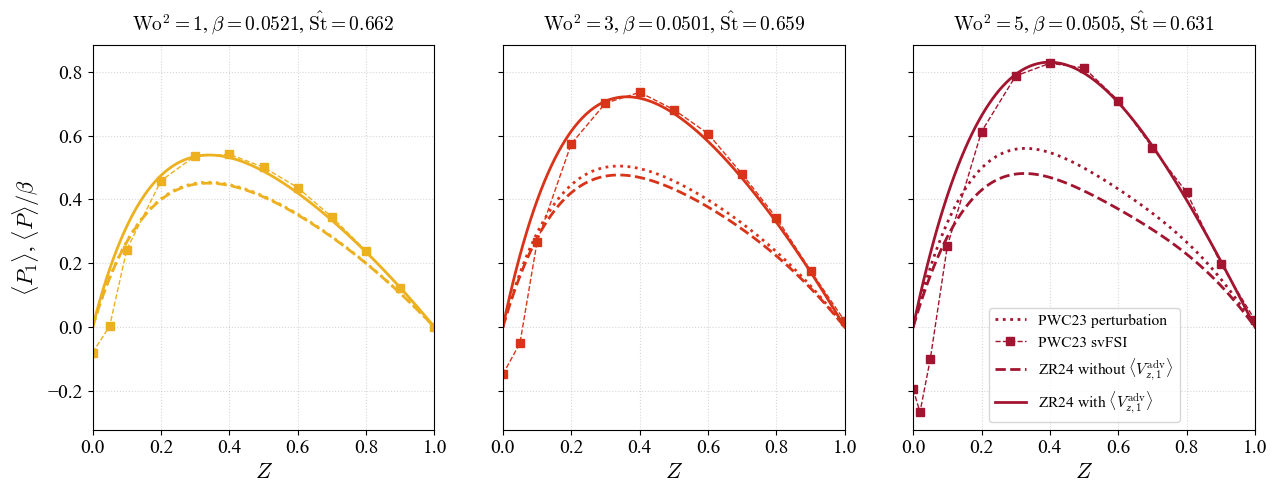

In [40]:
fig, axs = plt.subplots(1, len(sims), figsize=(15,5), sharey=True)

for ax, sim in zip(axs, sims):
  my_color = sim['color']
  ax.plot(my_Z, sim['PWC23'], lw=2, ls='dotted', color=my_color,
          label='PWC23 perturbation')
  ax.plot(sim['Z'], sim['P'], 's--', lw=1, color=my_color,
          label='PWC23 svFSI')
  ax.plot(my_Z, sim['ZR24'], lw=2, ls='dashed', color=my_color,
          label=r'ZR24 without $\langle V_{z,1}^\mathrm{adv} \rangle$')
  ax.plot(my_Z, sim['ZR24_adv'], lw=2, color=my_color,
          label=r'ZR24 with $\langle V_{z,1}^\mathrm{adv} \rangle$')
  ax.set_title(rf"$\mathrm{{Wo}}^2 = {sim['Wo']**2:.0f}$, $\beta = {sim['beta']}$, "
               rf"$\hat{{\mathrm{{St}}}} = {2*np.pi*sim['beta']*sim['Stf']:.3f}$",
               fontsize=size*0.875, pad=10)
  ax.set_xlabel('$Z$')
  ax.set_xlim(0, 1)
  ax.grid(alpha=0.5, linestyle='dotted')

axs[0].set_ylabel(r'$\langle P_1 \rangle$, $\langle P \rangle/\beta$')
axs[-1].legend(loc='lower center', fontsize=size*0.7)

plt.show()

With advective inertia included, the theory of [ZR24] agrees closely with the svFSI data away from the inlet, for all three Womersley numbers. The perturbation solution of the reduced PDE of [PWC23], and the theory of [ZR24] without advective inertia, underpredict the streaming pressure, increasingly so as $\mathrm{Wo}$ grows. Near $Z=0$, the svFSI data deviate from $\langle P \rangle = 0$ because the finite-element method enforces the pressure BC only weakly [PWC23].

# Summary

- The numerical solution of the reduced PDE of [PWC23] agrees with its $\mathrm{O}(\beta)$ perturbation solution, and the latter reduces to the closed-form result of [PWC23] as $\hat{\mathrm{St}}\to0$.
- Without advective inertia, the formulations of [PWC23] and [ZR24] differ in the resistance to the mean flow, in the flux generated by the wall motion, and in a storage term that enters only through the complex $\mathfrak{g}_0$. They agree as $\mathrm{Wo}\to0$ and separate as $\mathrm{Wo}$ grows.
- Advective inertia, which [ZR24] include but the reduced PDE of [PWC23] does not, is a large effect at the parameters of the svFSI simulations. Including it brings the theory into close agreement with the simulations away from the inlet.

# References

*   [GC19] A. A. Ghodgaonkar, I. C. Christov, Solving nonlinear parabolic equations by a strongly implicit finite difference scheme: applications to the finite speed spreading of non-Newtonian viscous gravity currents, in: _Applied Wave Mathematics II_, Springer, 2019, pp. 305&ndash;342. [doi:10.1007/978-3-030-29951-4_14](https://doi.org/10.1007/978-3-030-29951-4_14); [arXiv:1903.07568](https://arxiv.org/abs/1903.07568)

*   [PWC23] S. D. Pande, X. Wang, I. C. Christov, Oscillatory flows in compliant conduits at arbitrary Womersley number, _Phys. Rev. Fluids_ **8** (2023) 124102. [doi:10.1103/PhysRevFluids.8.124102](https://doi.org/10.1103/PhysRevFluids.8.124102); [arXiv:2304.00543](https://arxiv.org/abs/2304.00543)

*   [ZR24] X. Zhang, B. Rallabandi, Elasto-inertial rectification of oscillatory flow in an elastic tube, _J. Fluid Mech._ **996** (2024) A16. [doi:10.1017/jfm.2024.612](https://doi.org/10.1017/jfm.2024.612); [arXiv:2404.02292](https://arxiv.org/abs/2404.02292)